# 06 · Sharper intervals with CUPAC, and a guardrail that asks "does it pay?"

**Question.** Can signals known before sign-up make the always-valid interval narrower without breaking its guarantee? And how should the page stop a Starter Bonus that works but costs more than it earns?

**Milestone.** M9 · **Theory notes:** [variance-reduction](../docs/theory/variance-reduction.md), [anytime-valid](../docs/theory/anytime-valid.md), [power-mde](../docs/theory/power-mde.md)

## Where we are

Notebook 03 paid for safe peeking with a wider interval (about 1.55× the usual one). Notebook 01 found that signals known before sign-up (games installed, click-to-install time, the ad partner's score) carry real information about who will activate. Here we use them the way DoorDash's **CUPAC** does: train a model on an **earlier cohort**, use its prediction as the covariate in a CUPED adjustment, and plug the adjusted estimate into the same always-valid interval.

Then the guardrail. A lift above zero is not enough: notebook 04 showed the bonus only pays for itself above +1.71 points. The guardrail measures value per player and can block a ship.

## 1. Model

### CUPAC: CUPED with a prediction as the covariate

Train a model $\hat f$ on an earlier cohort (everyone on standard rewards, before the test) to predict activation from pre-sign-up features $Z_i$. In the experiment, each player's covariate is $X_i = \hat f(Z_i)$, computed at sign-up. The adjusted outcome is

$$
\tilde Y_i = Y_i - \theta\,(X_i - \mu_X), \qquad \theta = \frac{\operatorname{Cov}(Y, X)}{\operatorname{Var}(X)},
$$

with $\theta$ and $\mu_X$ also fixed from the earlier cohort. Because $X_i$ depends only on things known before assignment, and $\theta, \mu_X$ come from outside the experiment, the difference in means of $\tilde Y$ estimates exactly the same lift as before. Its variance is about $1 - R^2$ times smaller, where $R^2 = \operatorname{corr}(Y, X)^2$.

### Same interval, smaller standard error

The always-valid interval of notebook 03 only needs an average and its standard error. For the adjusted outcome, from running totals per arm ($n_a$, $\sum \tilde y$, $\sum \tilde y^2$):

$$
\hat\Delta^{\text{adj}}_n = \bar{\tilde y}_T - \bar{\tilde y}_C, \qquad
\widehat{\mathrm{SE}}^{\text{adj}}_n = \sqrt{s^2_{\tilde y,T}/n_T + s^2_{\tilde y,C}/n_C}, \qquad
\hat\Delta^{\text{adj}}_n \pm \widehat{\mathrm{SE}}^{\text{adj}}_n \, c_n .
$$

Fixing $\theta$ in advance is what keeps this simple and valid with running totals. (Estimating it inside the experiment, as Lin (2013) or GrowthBook's `RegressionAdjustedStatistic` do, is also valid asymptotically; we cross-check against an OLS fit at the end.)

### The guardrail: projected net value per player

Each activated player brings a lifetime net margin $V$ (notebook 04: \$2.50). The Starter Bonus adds a cost: the 40 coins (\$0.40) paid at level 5 to players who would never have reached level 10 (45% of activated players). We do not know at day 3 who those will be, so we use the expected cost $c = 0.40 \times 0.45 = \$0.18$ per activated Starter Bonus player. Value per player in each arm is then $V p_C$ and $(V - c)\,p_T$, and with $p_T = p_C + \Delta$ the difference is an exact function of the lift:

$$
G(\Delta) = (V - c)(p_C + \Delta) - V p_C = (V - c)\,\Delta - c\,p_C .
$$

$G$ is increasing in $\Delta$, so the always-valid CUPAC interval for the lift maps straight to an interval for value per player, with the running control rate $\hat p_C$ as a plug-in:

$$
\big[\,G(\hat\Delta^{\text{lo}}_n),\; G(\hat\Delta^{\text{hi}}_n)\,\big], \qquad G(\Delta) > 0 \iff \Delta > \Delta^\star = \frac{c\,p_C}{V - c} .
$$

So "pays" means exactly "the lift is shown above break-even" ($\Delta^\star$ is notebook 04's break-even, +1.71 points). An earlier draft gave the guardrail its own interval, built from a per-player value $G_i$; it was wider (no CUPAC) and could disagree with the lift row on the page. One interval, mapped through the economics, keeps every number on the page consistent. The plug-in $\hat p_C$ adds a little noise that the interval ignores; at 1,000+ control players it moves $G$ by well under a cent.

The traffic light reads the value interval:

- **red** (breached): the whole interval is below zero, so the bonus costs more than it brings;
- **green** (holding): the whole interval is above zero;
- **grey**: not clear yet.

**Decision rule.** *Ship* when the lift's interval is above zero **and** the guardrail is not red. When the lift is confirmed but the guardrail is red: *don't ship, it works but doesn't pay.*

> Assumption to revisit: the brief names "net revenue per player (studio payments minus rewards paid)". Measured only inside the 3-day window, that metric would penalise paying coins early while most of an activated player's value arrives later. We use the projected lifetime value instead, the same economics as the break-even in notebook 04.

## 2. Libraries

| Library | Used for |
|---|---|
| `ablab` | Production simulator, confidence sequence, planning functions |
| `scikit-learn` | `LogisticRegression` and `HistGradientBoostingClassifier` for the CUPAC model; `roc_auc_score` |
| `statsmodels` | OLS with interaction terms (Lin 2013) as a fixed-horizon cross-check; Wilson intervals |
| `numpy`, `pandas`, `matplotlib`, `seaborn` | Simulation, tables, figures |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from matplotlib.ticker import PercentFormatter
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from statsmodels.stats.proportion import proportion_confint

from ablab.config import load
from ablab.power import break_even_lift
from ablab.sequential import cs_multiplier, rho2_for
from ablab.simulator import raw_multiplier, simulate
from ablab.viz import use_style, savefig, CONTROL, TREAT, INK, MUTED, SHIP, STOP

use_style()
pd.set_option("display.precision", 4)
CFG = load()
PLAN = CFG["plan"]
ALPHA, N_MAX, MIN_N = PLAN["alpha"], PLAN["max_players"], PLAN["min_players"]
V = PLAN["value_per_activation_usd"]
EXTRA_COST = PLAN["bonus_usd"] * (1 - PLAN["p_reach_level10"])   # $0.18 per activated Starter Bonus player
BREAK_EVEN = break_even_lift(CFG["experiment"]["baseline_rate"], PLAN["p_reach_level10"], PLAN["bonus_usd"], V)
SEED = 20261019
print(f"seed {SEED}; V = ${V:.2f}, extra cost ${EXTRA_COST:.2f} per activated bonus player, break-even +{BREAK_EVEN * 100:.2f} points")


def rate(hits):
    k, n = int(np.sum(hits)), len(hits)
    lo, hi = proportion_confint(k, n, method="wilson")
    return pd.Series({"rate": k / n, "ci_low": lo, "ci_high": hi})

seed 20261019; V = $2.50, extra cost $0.18 per activated bonus player, break-even +1.71 points


## 3. Data

### The earlier cohort, and the CUPAC model

Two weeks of sign-ups before the test (everyone on standard rewards): train on the first, evaluate on the second.

In [2]:
FEATURES_SIGNUP = ["tier", "device", "channel", "evening"]
FEATURES_ALL = FEATURES_SIGNUP + ["log_games", "log_click", "partner_score", "has_score"]


def features(df):
    out = pd.DataFrame({
        "tier": df.tier, "device": df.device, "channel": df.channel, "evening": df.evening.astype(int),
        "log_games": np.log1p(df.games_30d), "log_click": np.log(df.click_to_install_s),
        "partner_score": df.partner_score.fillna(0.0), "has_score": df.partner_score.notna().astype(int),
    })
    return out


def design(F):
    """One-hot categories for the logistic model (portable: a weight per column)."""
    X = pd.get_dummies(F, columns=["tier", "device", "channel"], drop_first=True, dtype=float)
    return X


cohort, _ = simulate(0.0, seed=SEED)                       # before the test: no bonus anywhere
train_cohort, holdout = cohort[cohort.signup_hour < 7 * 24], cohort[cohort.signup_hour >= 7 * 24]
F_tr, F_ho = features(train_cohort), features(holdout)
y_tr, y_ho = train_cohort.activated.to_numpy(), holdout.activated.to_numpy()

models = {
    "Logistic, sign-up attributes": LogisticRegression(max_iter=1000).fit(design(F_tr[FEATURES_SIGNUP]), y_tr),
    "Logistic, + pre-sign-up signals": LogisticRegression(max_iter=1000).fit(design(F_tr[FEATURES_ALL]), y_tr),
    "Gradient boosting, + signals": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, random_state=0)
        .fit(F_tr[FEATURES_ALL], y_tr),
}


def predict(name, F):
    m = models[name]
    cols = FEATURES_SIGNUP if "sign-up attributes" in name else FEATURES_ALL
    X = design(F[cols]) if name.startswith("Logistic") else F[cols]
    return m.predict_proba(X)[:, 1]


quality = pd.DataFrame({
    name: {"variance removed (R²)": np.corrcoef(y_ho, predict(name, F_ho))[0, 1] ** 2,
           "AUC": roc_auc_score(y_ho, predict(name, F_ho))}
    for name in models
}).T
quality

,variance removed (R²),AUC
"Logistic, sign-up attributes",0.0167,0.5894
"Logistic, + pre-sign-up signals",0.1242,0.7285
"Gradient boosting, + signals",0.1248,0.7277


The logistic model with the signals does about as well as gradient boosting, and it is a list of weights the browser can apply to each new player. We use it. $\theta$ and $\mu_X$ are fixed on the holdout week.

In [3]:
CUPAC = "Logistic, + pre-sign-up signals"
x_ho = predict(CUPAC, F_ho)
THETA = np.cov(y_ho, x_ho)[0, 1] / x_ho.var(ddof=1)
MU_X = x_ho.mean()
R2 = quality.loc[CUPAC, "variance removed (R²)"]
weights = pd.Series(np.r_[models[CUPAC].intercept_, models[CUPAC].coef_[0]],
                    index=["intercept"] + list(design(F_tr[FEATURES_ALL]).columns))
print(f"theta = {THETA:.3f}, mu_X = {MU_X:.4f}, R² = {R2:.3f}")
weights.round(3).to_frame("weight")

theta = 1.017, mu_X = 0.2185, R² = 0.124


,weight
intercept,-0.990
evening,0.123
log_games,0.948
log_click,-0.287
partner_score,1.769
has_score,-0.744
tier_1,-0.239
tier_2,-0.549
device_1,-0.120
channel_1,-0.744


### A large population to draw experiments from

Four fresh fortnights of players from the production simulator, each scored by the CUPAC model at sign-up. Experiments below draw players from this pool, so every player is a full simulated player with signals, a true activation probability and a segment multiplier.

In [4]:
pool = pd.concat([simulate(0.0, seed=SEED + 100 + k)[0] for k in range(4)], ignore_index=True)
POOL_P0 = pool.p0.to_numpy()
POOL_M = np.asarray(raw_multiplier(pool)) / CFG["calibration"]["multiplier_mean"]
POOL_X = predict(CUPAC, features(pool))
print(f"pool: {len(pool):,} players, baseline {POOL_P0.mean():.3f}, mean score {POOL_X.mean():.3f}")

pool: 402,981 players, baseline 0.220, mean score 0.219


### Simulating experiments

Each run draws 30,000 players from the pool, assigns each to an arm with a fair coin (as the hash does), draws activation from their own true probability, and keeps per-arm running totals of $Y$ and $\tilde Y$ after every 500 players. The guardrail interval is the CUPAC lift interval passed through $G$.

In [5]:
LOOK = 500
LOOKS = N_MAX // LOOK


def run_batch(lift, runs, rng):
    idx = rng.integers(0, len(POOL_P0), size=(runs, N_MAX))
    arm = rng.random((runs, N_MAX)) < 0.5
    p = POOL_P0[idx] + arm * lift * POOL_M[idx]
    y = (rng.random((runs, N_MAX)) < p).astype(float)
    y_adj = y - THETA * (POOL_X[idx] - MU_X)
    out = {}
    for name, v in [("y", y), ("adj", y_adj)]:
        for a, mask in [("t", arm), ("c", ~arm)]:
            vv = np.where(mask, v, 0.0).reshape(runs, LOOKS, LOOK)
            out[f"{name}_{a}_s"] = vv.sum(2).cumsum(1)
            out[f"{name}_{a}_ss"] = (vv**2).sum(2).cumsum(1)
    for a, mask in [("t", arm), ("c", ~arm)]:
        out[f"n_{a}"] = mask.reshape(runs, LOOKS, LOOK).sum(2).cumsum(1)
    return out


def interval(tot, name, alpha=ALPHA, n_star=PLAN["n_star"]):
    n_t, n_c = tot["n_t"], tot["n_c"]
    m_t, m_c = tot[f"{name}_t_s"] / n_t, tot[f"{name}_c_s"] / n_c
    v_t = (tot[f"{name}_t_ss"] - n_t * m_t**2) / (n_t - 1)
    v_c = (tot[f"{name}_c_ss"] - n_c * m_c**2) / (n_c - 1)
    d, se, n = m_t - m_c, np.sqrt(v_t / n_t + v_c / n_c), n_t + n_c
    half = se * cs_multiplier(n, rho2_for(n_star, alpha), alpha)
    lo, hi = np.where(n >= MIN_N, d - half, -np.inf), np.where(n >= MIN_N, d + half, np.inf)
    return {"d": d, "se": se, "n": n, "lo": np.maximum.accumulate(lo, 1), "hi": np.minimum.accumulate(hi, 1)}


def value_from_lift(lift, p_c):
    """G(lift) = (V - c) lift - c p_C: value per player, Starter Bonus minus standard ($)."""
    return (V - EXTRA_COST) * lift - EXTRA_COST * p_c


def guardrail(tot, adj):
    """The CUPAC lift interval mapped to value per player, with the running control rate as p_C."""
    p_c = tot["y_c_s"] / tot["n_c"]
    return {"d": value_from_lift(adj["d"], p_c), "lo": value_from_lift(adj["lo"], p_c),
            "hi": value_from_lift(adj["hi"], p_c), "n": adj["n"]}


LIFTS = {"No effect": 0.0, "Below break-even (+1.0)": 0.01, "Break-even": BREAK_EVEN,
         "Small (+2.0)": 0.02, "Large (+5.0)": 0.05}
R, CHUNK = 1_000, 100
rng = np.random.default_rng(SEED)
sims = {}
for label, lift in LIFTS.items():
    parts = [run_batch(lift, CHUNK, rng) for _ in range(R // CHUNK)]
    tot = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
    adj = interval(tot, "adj")
    sims[label] = {"lift": lift, "raw": interval(tot, "y"), "adj": adj, "g": guardrail(tot, adj)}
print({k: v["raw"]["n"].shape for k, v in sims.items()})

{'No effect': (1000, 60), 'Below break-even (+1.0)': (1000, 60), 'Break-even': (1000, 60), 'Small (+2.0)': (1000, 60), 'Large (+5.0)': (1000, 60)}


## 4. Descriptives

### Is the CUPAC interval still valid?

In [6]:
def ever_excludes_zero(res):
    return ((res["lo"] > 0) | (res["hi"] < 0)).any(1)


def covers(res, truth):
    return ((res["lo"] <= truth) & (truth <= res["hi"])).all(1)


validity = pd.DataFrame({
    (design_, check): (rate(ever_excludes_zero(sims["No effect"][key])) if check == "false verdicts, no effect"
                       else rate(covers(sims[label][key], sims[label]["lift"])))
    for design_, key in [("Unadjusted", "raw"), ("CUPAC", "adj")]
    for check, label in [("false verdicts, no effect", None), ("coverage, small effect", "Small (+2.0)"),
                         ("coverage, large effect", "Large (+5.0)")]
}).T
validity

rate  ci_low  ci_high
Unadjusted false verdicts, no effect  0.019  0.0122   0.0295
           coverage, small effect     0.986  0.9766   0.9916
           coverage, large effect     0.985  0.9754   0.9909
CUPAC      false verdicts, no effect  0.017  0.0106   0.0271
           coverage, small effect     0.988  0.9791   0.9931
           coverage, large effect     0.989  0.9804   0.9938

### How much narrower, and how much sooner?

In [7]:
width_ratio = (sims["Small (+2.0)"]["adj"]["se"] / sims["Small (+2.0)"]["raw"]["se"]).mean(0)
print(f"CUPAC interval width / unadjusted, average over runs: {width_ratio[5]:.3f} at {sims['Small (+2.0)']['raw']['n'][0, 5]:,.0f} "
      f"players, {width_ratio[-1]:.3f} at 30,000  (theory: sqrt(1 - R²) = {np.sqrt(1 - R2):.3f})")


def ship_stats(res):
    hit = res["lo"] > 0
    shipped = hit.any(1)
    n_at = np.where(shipped, res["n"][np.arange(R), hit.argmax(1)], np.nan)
    return shipped, n_at


speed = pd.DataFrame([
    {"true lift": label, "design": design_, "ships by 30,000": ship_stats(s[key])[0].mean(),
     "median players at ship": np.nanmedian(ship_stats(s[key])[1]) if ship_stats(s[key])[0].any() else np.nan}
    for label, s in sims.items() if s["lift"] > 0 for design_, key in [("Unadjusted", "raw"), ("CUPAC", "adj")]
])
speed.pivot(index="true lift", columns="design", values=["ships by 30,000", "median players at ship"]).round(3)

CUPAC interval width / unadjusted, average over runs: 0.937 at 3,000 players, 0.937 at 30,000  (theory: sqrt(1 - R²) = 0.936)


ships by 30,000            median players at ship  \
design                            CUPAC Unadjusted                  CUPAC   
true lift                                                                   
Below break-even (+1.0)           0.316      0.264                20000.0   
Break-even                        0.825      0.755                16000.0   
Large (+5.0)                      1.000      1.000                 3500.0   
Small (+2.0)                      0.956      0.916                13000.0   

                                    
design                  Unadjusted  
true lift                           
Below break-even (+1.0)    19500.0  
Break-even                 16500.0  
Large (+5.0)                4000.0  
Small (+2.0)               14000.0

### The guardrail and the final verdict

At the end of each run (the first verdict, or 30,000 players), the guardrail light and the combined verdict. True value per player is known for each scenario.

In [8]:
def light(g, k):
    """Guardrail light at look index k for each run."""
    lo, hi = g["lo"][:, k], g["hi"][:, k]
    return np.where(hi < 0, "red", np.where(lo > 0, "green", "grey"))


def final_verdicts(s):
    adj, g = s["adj"], s["g"]
    lift_ship = adj["lo"] > 0
    lift_stop = adj["hi"] < 0
    out = []
    for r in range(R):
        k_ship = np.argmax(lift_ship[r]) if lift_ship[r].any() else None
        k_stop = np.argmax(lift_stop[r]) if lift_stop[r].any() else None
        if k_stop is not None and (k_ship is None or k_stop < k_ship):
            out.append(("Don't ship", light(g, k_stop)[r]))
        elif k_ship is not None:
            # the lift is confirmed: ship unless the guardrail is red at that moment
            if g["hi"][r, k_ship] < 0:
                out.append(("Don't ship: doesn't pay", "red"))
            else:
                out.append(("Ship", light(g, k_ship)[r]))
        else:
            out.append(("Inconclusive", light(g, LOOKS - 1)[r]))
    return pd.DataFrame(out, columns=["verdict", "guardrail"])


true_value = {label: V * s["lift"] - EXTRA_COST * (CFG["experiment"]["baseline_rate"] + s["lift"]) for label, s in sims.items()}
verdicts = {label: final_verdicts(s) for label, s in sims.items()}
mix = pd.DataFrame({label: v.verdict.value_counts(normalize=True) for label, v in verdicts.items()}).fillna(0).T
mix.insert(0, "true value per player ($)", pd.Series(true_value))
mix.round(3)

verdict,true value per player ($),Don't ship,Don't ship: doesn't pay,Inconclusive,Ship
No effect,-0.040,0.011,0.000,0.983,0.006
Below break-even (+1.0),-0.016,0.000,0.001,0.684,0.315
Break-even,0.000,0.000,0.000,0.175,0.825
Small (+2.0),0.007,0.000,0.000,0.044,0.956
Large (+5.0),0.076,0.000,0.000,0.000,1.000


### Two possible rules: "it works" or "it pays"

The table above uses the brief's rule (ship when the lift is above zero and the guardrail is not red). It barely blocks anything. The light is red only when the whole lift interval sits below break-even, and at the moment the lift is shown above zero the interval still spans more than 0 to +1.71 points, so the light is almost always grey and grey lets the ship through. In money: the guardrail's interval is about ±2.9¢ per player at 30,000 players (it is the CUPAC lift interval times $V - c$), while the economics differ by 1–2¢.

The stricter rule ships only when the value per player is **shown** to be positive (guardrail green). With the guardrail derived from the lift, this is exactly "the lift's lower bound is above break-even", rather than above zero.

In [9]:
def ship_rate(s, rule):
    adj, g = s["adj"], s["g"]
    if rule == "works":
        ok = (adj["lo"] > 0) & ~(g["hi"] < 0)
    else:
        ok = (adj["lo"] > 0) & (g["lo"] > 0)
    shipped = ok.any(1)
    n_at = np.where(shipped, adj["n"][np.arange(R), ok.argmax(1)], np.nan)
    return shipped.mean(), (np.nanmedian(n_at) if shipped.any() else np.nan)


rules = pd.DataFrame([
    {"true lift": label, "true value per player ($)": true_value[label],
     "ships: 'it works' (brief)": ship_rate(s, "works")[0], "ships: 'it pays' (strict)": ship_rate(s, "pays")[0],
     "median players, 'it pays'": ship_rate(s, "pays")[1]}
    for label, s in sims.items()
]).set_index("true lift")
g_end = sims["Small (+2.0)"]["g"]
half_value = (g_end["hi"][:, -1] - g_end["lo"][:, -1]).mean() / 2 * 100
print(f"guardrail interval at 30,000 players: ±{half_value:.1f}¢ per player")
rules.round(3)

guardrail interval at 30,000 players: ±2.9¢ per player


,true value per player ($),ships: 'it works' (brief),ships: 'it pays' (strict),"median players, 'it pays'"
true lift,,,,
No effect,-0.040,0.006,0.000,NaN
Below break-even (+1.0),-0.016,0.315,0.002,10500.0
Break-even,0.000,0.825,0.011,8000.0
Small (+2.0),0.007,0.956,0.033,13000.0
Large (+5.0),0.076,1.000,1.000,6500.0


### Cross-check with a regression (Lin 2013), at one look

For one run at 30,000 players, the CUPAC estimate and standard error next to an OLS of $Y$ on arm, centred score and their interaction, with robust (HC2) errors. They should agree closely.

In [10]:
cross_rng = np.random.default_rng(SEED + 7)
idx = cross_rng.integers(0, len(POOL_P0), N_MAX)
arm = cross_rng.random(N_MAX) < 0.5
y = (cross_rng.random(N_MAX) < POOL_P0[idx] + arm * 0.02 * POOL_M[idx]).astype(float)
xc = POOL_X[idx] - MU_X
df_x = pd.DataFrame({"y": y, "arm": arm.astype(int), "xc": xc})
lin = smf.ols("y ~ arm * xc", data=df_x).fit(cov_type="HC2")
y_adj = y - THETA * xc
cupac_d = y_adj[arm].mean() - y_adj[~arm].mean()
cupac_se = np.sqrt(y_adj[arm].var(ddof=1) / arm.sum() + y_adj[~arm].var(ddof=1) / (~arm).sum())
raw_se = np.sqrt(y[arm].var(ddof=1) / arm.sum() + y[~arm].var(ddof=1) / (~arm).sum())
pd.DataFrame({"estimate": [y[arm].mean() - y[~arm].mean(), cupac_d, lin.params["arm"]],
              "standard error": [raw_se, cupac_se, lin.bse["arm"]]},
             index=["Unadjusted", "CUPAC (theta fixed from the earlier cohort)", "Lin OLS, HC2 (statsmodels)"]).round(5)

,estimate,standard error
Unadjusted,0.0223,0.0049
CUPAC (theta fixed from the earlier cohort),0.0205,0.0046
"Lin OLS, HC2 (statsmodels)",0.0205,0.0045


## 5. Figures

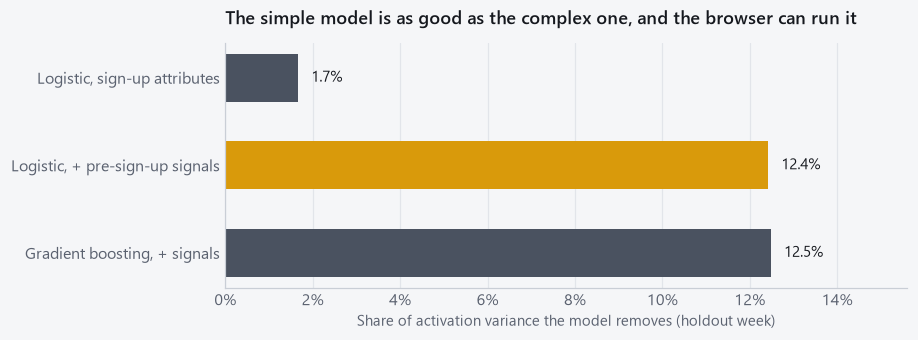

In [11]:
fig, ax = plt.subplots(figsize=(8, 2.9))
q = quality["variance removed (R²)"]
ax.barh(q.index[::-1], q.values[::-1], color=[CONTROL, TREAT, CONTROL][::-1], height=0.55)
for yv, v in enumerate(q.values[::-1]):
    ax.text(v + 0.003, yv, f"{v:.1%}", va="center", fontsize=10)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, q.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("Share of activation variance the model removes (holdout week)")
ax.set_title("The simple model is as good as the complex one, and the browser can run it")
savefig(fig, "06_cupac_models")

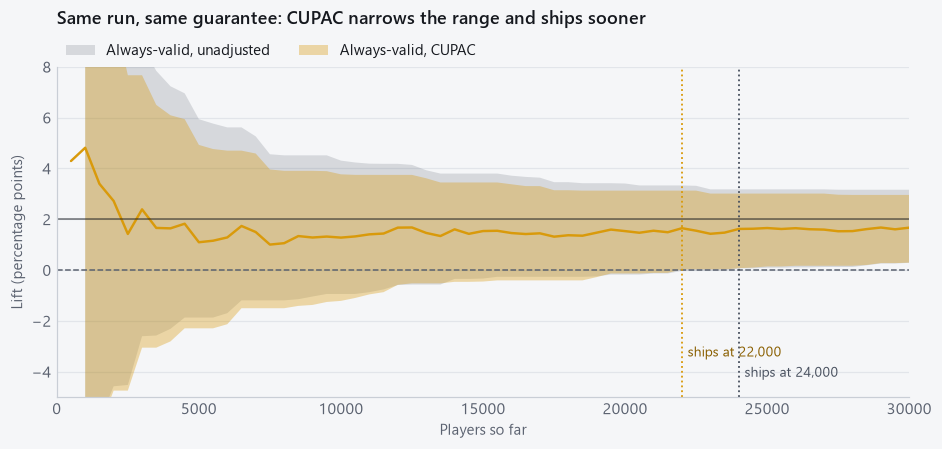

In [12]:
s = sims["Small (+2.0)"]
# a representative run: both ship, CUPAC earlier by about the median gap
both = ship_stats(s["adj"])[0] & ship_stats(s["raw"])[0]
gap = ship_stats(s["raw"])[1] - ship_stats(s["adj"])[1]
target = np.nanmedian(gap[both & (gap > 0)])
r = int(np.nanargmin(np.where(both & (gap > 0), np.abs(gap - target), np.nan)))
n = s["raw"]["n"][r]
fig, ax = plt.subplots(figsize=(10, 3.9))
for key, color, alpha_, label in [("raw", CONTROL, 0.18, "Always-valid, unadjusted"), ("adj", TREAT, 0.35, "Always-valid, CUPAC")]:
    lo, hi = s[key]["lo"][r], s[key]["hi"][r]
    m = np.isfinite(lo)
    ax.fill_between(n[m], lo[m] * 100, hi[m] * 100, color=color, alpha=alpha_, lw=0, label=label)
ax.plot(n, s["adj"]["d"][r] * 100, color=TREAT, lw=1.6)
ax.axhline(0, color=MUTED, ls="--", lw=1)
ax.axhline(2, color=INK, lw=1, alpha=0.6)
for key, color in [("raw", CONTROL), ("adj", TREAT)]:
    k = int(np.argmax(s[key]["lo"][r] > 0))
    ax.axvline(n[k], color=color, lw=1.2, ls=":")
    ax.text(n[k] + 200, -3.4 if key == "adj" else -4.2, f"ships at {n[k]:,}", color=color if key == "raw" else "#8a5f00", fontsize=9)
ax.set_ylim(-5, 8)
ax.set_xlim(0, N_MAX)
ax.set_xlabel("Players so far")
ax.set_ylabel("Lift (percentage points)")
ax.set_title("Same run, same guarantee: CUPAC narrows the range and ships sooner", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, borderaxespad=0.2)
savefig(fig, "06_one_run_cupac")

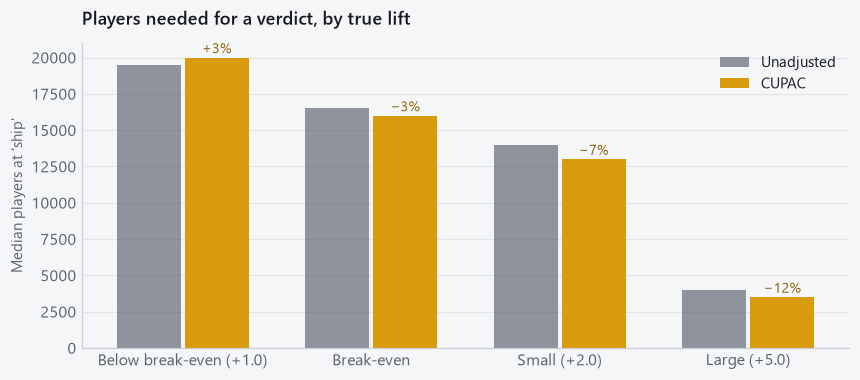

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.6))
sp = speed.pivot(index="true lift", columns="design", values="median players at ship").reindex(
    [k for k in LIFTS if LIFTS[k] > 0])
xs = np.arange(len(sp))
ax.bar(xs - 0.18, sp["Unadjusted"], width=0.34, color=CONTROL, alpha=0.6, label="Unadjusted")
ax.bar(xs + 0.18, sp["CUPAC"], width=0.34, color=TREAT, label="CUPAC")
for x, (u, c) in enumerate(zip(sp["Unadjusted"], sp["CUPAC"])):
    if np.isfinite(u) and np.isfinite(c):
        ax.text(x + 0.18, c + 300, f"{c / u - 1:+.0%}".replace("-", "−"), ha="center", fontsize=9, color="#8a5f00")
ax.set_xticks(xs, sp.index)
ax.set_ylabel("Median players at 'ship'")
ax.set_title("Players needed for a verdict, by true lift")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
savefig(fig, "06_players_to_ship")

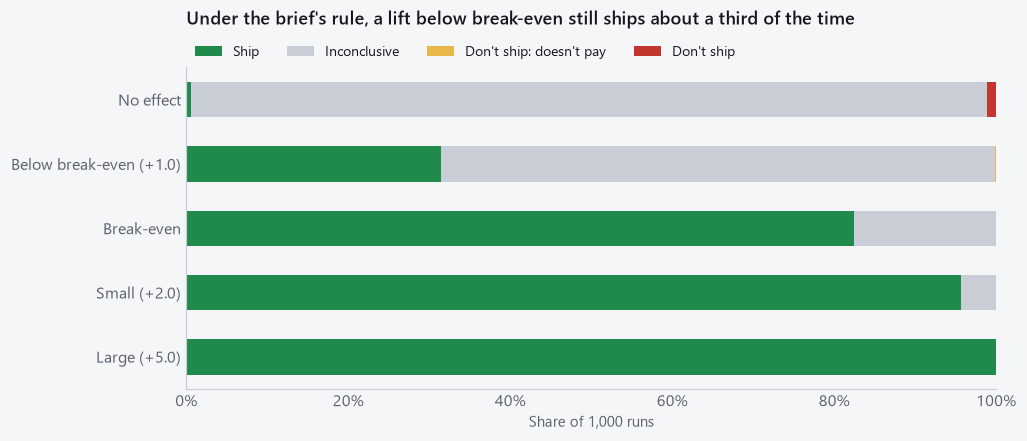

In [14]:
order = ["Ship", "Inconclusive", "Don't ship: doesn't pay", "Don't ship"]
palette = {"Ship": SHIP, "Inconclusive": "#c9ced6", "Don't ship: doesn't pay": "#e8b84a", "Don't ship": STOP}
fig, ax = plt.subplots(figsize=(9.5, 3.8))
left = np.zeros(len(mix))
labels = list(mix.index)
for v in order:
    vals = mix[v].to_numpy() if v in mix else np.zeros(len(mix))
    ax.barh(labels[::-1], vals[::-1], left=left[::-1], color=palette[v], label=v, height=0.55)
    left += vals
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of 1,000 runs")
ax.set_title("Under the brief's rule, a lift below break-even still ships about a third of the time", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=4, borderaxespad=0.2, fontsize=9)
savefig(fig, "06_verdict_mix")

## 6. Results

In [15]:
v = validity
print(f"False verdicts, no effect: unadjusted {v.loc[('Unadjusted', 'false verdicts, no effect'), 'rate']:.2%}, "
      f"CUPAC {v.loc[('CUPAC', 'false verdicts, no effect'), 'rate']:.2%}")
print(f"Coverage, small effect: unadjusted {v.loc[('Unadjusted', 'coverage, small effect'), 'rate']:.1%}, "
      f"CUPAC {v.loc[('CUPAC', 'coverage, small effect'), 'rate']:.1%}")
print(f"Width ratio at 30,000: {width_ratio[-1]:.3f} (theory {np.sqrt(1 - R2):.3f})")
print("Verdicts by true lift:")
print(mix.drop(columns="true value per player ($)").round(3).to_string())

False verdicts, no effect: unadjusted 1.90%, CUPAC 1.70%
Coverage, small effect: unadjusted 98.6%, CUPAC 98.8%
Width ratio at 30,000: 0.937 (theory 0.936)
Verdicts by true lift:
verdict                  Don't ship  Don't ship: doesn't pay  Inconclusive   Ship
No effect                     0.011                    0.000         0.983  0.006
Below break-even (+1.0)       0.000                    0.001         0.684  0.315
Break-even                    0.000                    0.000         0.175  0.825
Small (+2.0)                  0.000                    0.000         0.044  0.956
Large (+5.0)                  0.000                    0.000         0.000  1.000


- **CUPAC keeps the guarantee.** False verdicts under no effect and coverage at every look match the unadjusted interval; the adjustment only uses information from before assignment, with $\theta$ fixed outside the experiment.
- **It narrows the interval by the predicted amount**, about $\sqrt{1 - R^2}$, and real effects ship with fewer players (see the bar chart): days of traffic saved for free, as notebook 04 projected.
- **A simple model is enough.** Logistic regression on the pre-sign-up signals removes about as much variance as gradient boosting, and the browser can apply its weights to each player at sign-up.
- **The guardrail, as the brief defines it, barely bites.** Below break-even (+1.0 point) the bonus loses money, yet the page ships in about a third of runs: the guardrail is almost always grey at the moment the lift is confirmed, and grey does not block. 30,000 players are enough to show the bonus *works*, not to show it *pays* when the lift is near break-even (value per player is measured to about ±2.9¢; the differences that matter are 1–2¢).
- **The strict rule ("ship only when value is shown positive") blocks unprofitable lifts but needs much bigger effects.** See the rules table: it almost never ships below break-even, but also ships the Small preset (+2.0, only 0.3 points above break-even) in just 3% of runs. Only effects well above break-even pass it. Choosing between the two rules is a product decision, not a statistical one.
- **Cross-check.** At one look, the CUPAC estimate and its standard error agree with an OLS regression with interactions and robust errors (Lin 2013).

## 7. What gets promoted

| Item | Goes to | Guarded by |
|---|---|---|
| CUPAC model weights, $\theta$, $\mu_X$ | `config/cupac.json` (trained on the earlier cohort) | `tests/test_cupac.py`: weights reproduce the notebook's predictions |
| Adjusted running totals and interval | `ablab/sequential.py` / TS `run.ts`: the verdict uses the CUPAC interval | `validity/always_valid.py` extended to the adjusted interval; parity fixtures |
| Guardrail: value from the CUPAC lift, and the light | `ablab/guardrail.py` (`value_from_lift`), TS `guardrail.ts` (`valueFromLift`) | tests: light rules; parity cell below; `validity/cupac.py` |
| Verdict rule with the guardrail | `verdict()` gains the guardrail input and the 'doesn't pay' state | tests for every combination |

## 8. Production parity

The CUPAC model is trained by `scripts/train_cupac.py` into `config/cupac.json` (same cohort seed), applied by `ablab/cupac.py` and the browser's `cupac.ts`; the guardrail lives in `ablab/guardrail.py`; `validity/cupac.py` re-runs this notebook's checks.

In [16]:
from ablab import cupac as prod  # noqa: E402

stored = prod.load()
assert stored["cohort_seed"] == SEED
assert abs(stored["theta"] - THETA) < 1e-9 and abs(stored["mu"] - MU_X) < 1e-12
assert np.allclose(prod.score(holdout, stored), x_ho, atol=1e-12)
print("config/cupac.json and ablab.cupac reproduce this notebook's model")

from ablab import guardrail as prod_g  # noqa: E402

g_small = sims["Small (+2.0)"]["g"]
p_c_run = (g_small["d"] - (V - EXTRA_COST) * sims["Small (+2.0)"]["adj"]["d"]) / -EXTRA_COST
assert np.allclose(prod_g.value_from_lift(sims["Small (+2.0)"]["adj"]["lo"], p_c_run, PLAN), g_small["lo"], equal_nan=True)
assert prod_g.extra_cost(PLAN) == EXTRA_COST
assert abs(EXTRA_COST * CFG["experiment"]["baseline_rate"] / (V - EXTRA_COST) - BREAK_EVEN) < 1e-12
print("ablab.guardrail.value_from_lift reproduces this notebook's guardrail; G(lift) > 0 exactly above break-even")

config/cupac.json and ablab.cupac reproduce this notebook's model
ablab.guardrail.value_from_lift reproduces this notebook's guardrail; G(lift) > 0 exactly above break-even


## Further reading

Narrower intervals from pre-experiment information, and the economics behind the guardrail. Where to find them: **[local]** = `docs/papers/` in this project (kept out of the repo) · **[Vega: folder]** = `Vega/paper-library/pdfs/<folder>/` (Vega's library also has text versions in `paper-library/md/` and notes in `paper-library/papers/`) · **[airline library: folder]** = `Projects/airline-experimentation/paper-library/pdfs/<folder>/` (a copy of Vega's library plus airline-related extras) · **[online]** = not in any library yet. ★ = read first.

Theory notes in this project: [variance-reduction](../docs/theory/variance-reduction.md).

- ★ Deng, A., Xu, Y., Kohavi, R., & Walker, T. (2013). Improving the sensitivity of online controlled experiments by utilizing pre-experiment data. *WSDM 2013*. CUPED. **[local]** `2013-02CUPEDImprovingSensitivityOfControlledExperiments.pdf` (also Vega: 05-power-and-decisions)
- ★ Li, J. (2020). Improving experimental power through control using predictions as covariate (CUPAC). DoorDash Engineering blog. **[local]** `Improving Experimental Power ... (CUPAC) - DoorDash.pdf`
- Lin, W. (2013). Agnostic notes on regression adjustments to experimental data: reexamining Freedman's critique. *Annals of Applied Statistics* 7(1). Why regression adjustment is safe in experiments. **[online]** https://doi.org/10.1214/12-AOAS583
- Hosseini, R., & Najmi, A. (2019). Unbiased variance reduction in randomized experiments. arXiv:1904.03817. Any predictive model, kept unbiased. **[local]** `1904.03817v1.pdf`
- Williamson, E. J., Forbes, A., & White, I. R. (2014). Variance reduction in randomised trials by inverse probability weighting using the propensity score. *Statistics in Medicine* 33(5). The same idea from clinical trials. **[local]** `Statistics in Medicine - 2013 - Williamson ...pdf`
- Lindon, M., Ham, D. W., Tingley, M., & Bojinov, I. (2022). Anytime-valid linear models and regression adjusted causal inference in randomized experiments. arXiv:2210.08589. Regression adjustment *and* continuous monitoring together. **[online]** https://arxiv.org/abs/2210.08589
- Pankratev, S. (2026). Design-aware variance reduction for switchback experiments: a comparative study (CUPED, CUPAC, doubly robust). arXiv:2606.27662. **[local]** `2606.27662v2.pdf`
- Pankratev, S. (2026). Power-optimal covariate adjustment for switchback experiments. arXiv:2607.27376. How to train the CUPAC model for power. **[local]** `2607.27376v1.pdf`
- Schultzberg, M., Ankargren, S., & Frånberg, M. (2024). Risk-aware product decisions in A/B tests with multiple metrics. arXiv:2402.11609. Guardrails as non-inferiority tests. **[Vega: 05-power-and-decisions]**